### Q3: is Wav2Vec2 better with little data, or are the small models just under-trained?
On `sc_small` (320 clips) the CNN and ResNet in the main run made only about 10 steps per epoch, 100 to 200 steps in total.
That may not be enough to converge, so "Wav2Vec2 wins with little data" could simply mean "the others did not finish".
We train the same models on the same 320 clips for much longer and see where the accuracy stops growing.

If the CNN/ResNet curves reach a plateau and Wav2Vec2 is still far above, pre-training really helps.
If they catch up, the main claim has to be weakened.

In [1]:
import os
import sys
os.environ['PYTORCH_ENABLE_MPS_FALLBACK'] = '1'
sys.path.insert(0, '../src')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import extra
import metrics
from data import CONDITIONS, EXTRA_CONDITIONS, make_augment
import models

W1117 01:03:41.453000 45096 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


In [2]:
SEEDS = [0, 1]
EPOCHS = {'cnn': [20, 60, 150], 'resnet': [15, 60, 150], 'wav2vec': [10, 30]}  # first value is what the main run used

#### Training

In [3]:
for model, grid in EPOCHS.items():
    for epochs in grid:
        for seed in SEEDS:
            print(model, epochs, seed, flush=True)
            extra.collect_logits('sc_small', model, seed, epochs=epochs, tag=f'ep{epochs}')

cnn 20 0


    epoch 1/20  val_loss 2.286  1s


    epoch 2/20  val_loss 2.243  1s


    epoch 3/20  val_loss 2.170  2s


    epoch 4/20  val_loss 2.111  2s


    epoch 5/20  val_loss 2.004  3s


... (1,004 outputs left out)

    epoch 27/30  val_loss 0.282  375s


    epoch 28/30  val_loss 0.282  390s


    epoch 29/30  val_loss 0.282  404s


    epoch 30/30  val_loss 0.282  417s


#### Accuracy against training length

In [4]:
rows = []
for model, grid in EPOCHS.items():
    for epochs in grid:
        for seed in SEEDS:
            d = extra.collect_logits('sc_small', model, seed, epochs=epochs, tag=f'ep{epochs}')
            for condition in ['clean', 'white_0', 'real_0']:
                rows.append({'model': model, 'epochs': epochs, 'steps': epochs * (320 // models.BATCH_SIZE[model]), 'seed': seed,
                             'condition': condition, **extra.calib(d[f'test_{condition}'], d['y_test'])})
res = pd.DataFrame(rows)
res[res.condition == 'clean'].groupby(['model', 'epochs', 'steps'])[['acc', 'ece']].mean().round(3)

acc    ece
model   epochs steps              
cnn     20     200    0.603  0.240
        60     600    0.766  0.120
        150    1500   0.789  0.017
resnet  15     150    0.521  0.029
        60     600    0.635  0.143
        150    1500   0.655  0.169
wav2vec 10     200    0.954  0.041
        30     600    0.957  0.011

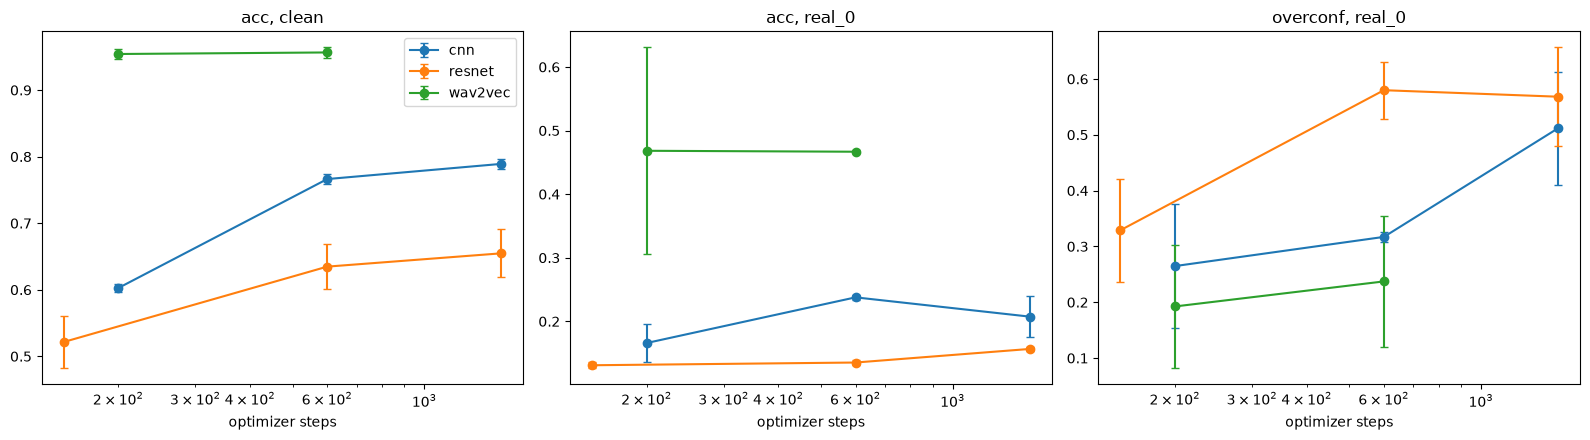

In [5]:
COLORS = {'cnn': 'tab:blue', 'resnet': 'tab:orange', 'wav2vec': 'tab:green'}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (condition, metric) in zip(axes, [('clean', 'acc'), ('real_0', 'acc'), ('real_0', 'overconf')]):
    for model in EPOCHS:
        part = res[(res.model == model) & (res.condition == condition)].groupby('steps')[metric].agg(['mean', 'std']).fillna(0)
        ax.errorbar(part.index, part['mean'], yerr=part['std'], marker='o', capsize=3, color=COLORS[model], label=model)
    ax.set_xscale('log'); ax.set_xlabel('optimizer steps'); ax.set_title(f'{metric}, {condition}')
axes[0].legend()
plt.tight_layout(); extra.save(fig, 'q3_undertraining'); plt.show()

Check two things: (1) do CNN and ResNet stop improving, and where, (2) is Wav2Vec2 still ahead at the same number of steps.